# Student Performance Prediction
### Machine Learning Project — Mathematics Dataset

**Team members:** Tanmay Raghav, Aditya Sirohi, Ritivik Sharma  
**Submitted to:** Professor Nirbhay  
**Academic Year:** 2026

This notebook predicts students' final Mathematics grade (`G3`) using two regression models:
1. Linear Regression
2. Random Forest Regressor

**Dataset:** UCI Student Performance — Mathematics subset (`student-mat.csv`), containing 395 records and 33 attributes.

> Keep `student-mat.csv` in the same folder as this notebook before running the cells. Install the required libraries with `python -m pip install -r requirements.txt` if they are not already installed.

## 1. Import Libraries

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Create a folder to store graphs and result files.
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Keep graph appearance consistent.
sns.set_theme(style="whitegrid")

## 2. Load the Dataset

The CSV file uses a semicolon (`;`) as its separator.

In [23]:
DATA_URL = "https://raw.githubusercontent.com/Tanmayraghav/DATA-SCIENCE-/main/data/student-mat.csv"

df = pd.read_csv(DATA_URL, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 3. Understand and Check the Data

In [24]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.dtypes

Number of rows and columns: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:


,0
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


In [25]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows, if any.
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate rows: 0
Shape after removing duplicates: (395, 33)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Final Grades (G3)

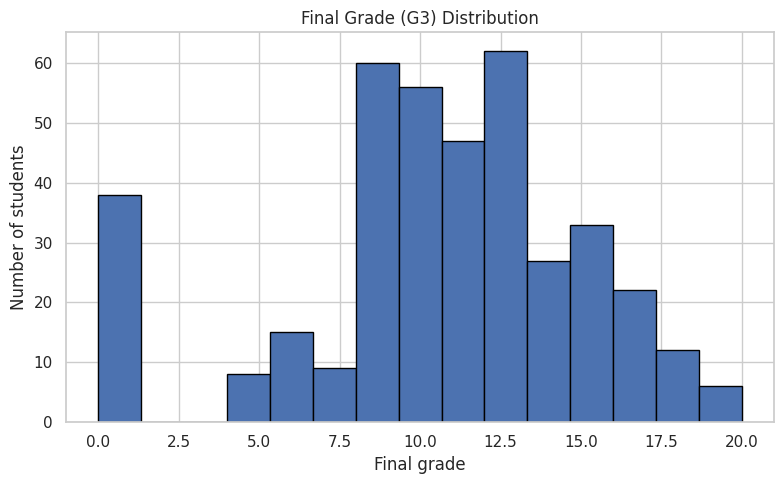

In [26]:
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=15, edgecolor="black")
plt.title("Final Grade (G3) Distribution")
plt.xlabel("Final grade")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "grade_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Study Time vs Final Grade

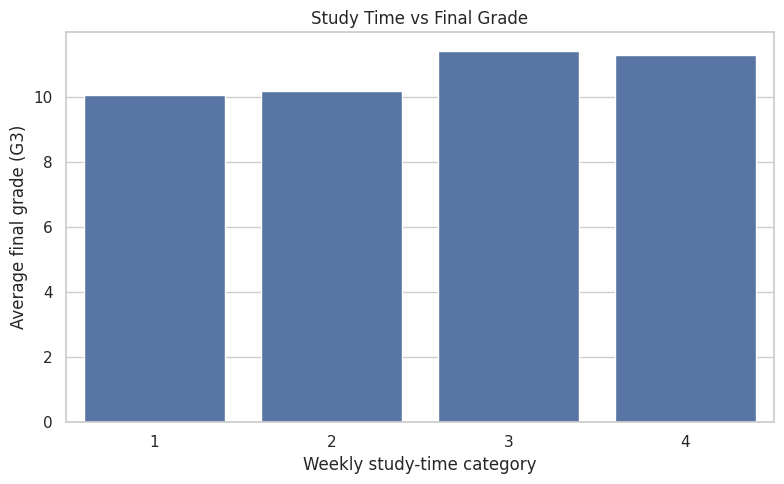

In [27]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="studytime", y="G3", errorbar=None)
plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly study-time category")
plt.ylabel("Average final grade (G3)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "study_time_vs_grade.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.3 Second-Period Grade (G2) vs Final Grade (G3)

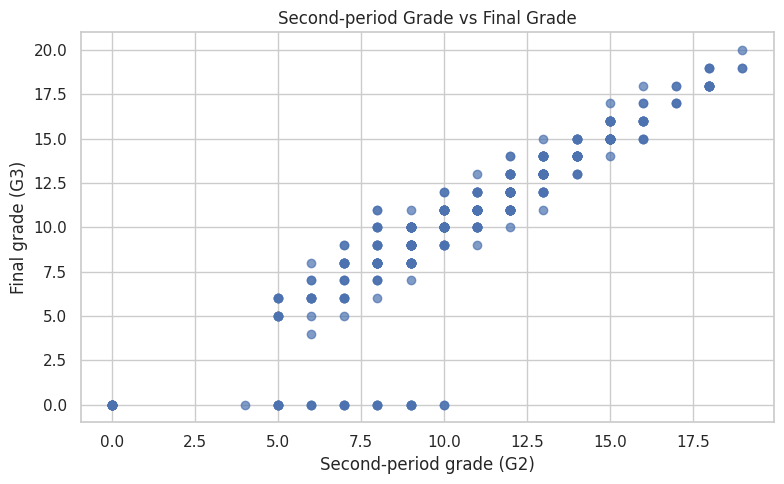

In [28]:
plt.figure(figsize=(8, 5))
plt.scatter(df["G2"], df["G3"], alpha=0.7)
plt.xlabel("Second-period grade (G2)")
plt.ylabel("Final grade (G3)")
plt.title("Second-period Grade vs Final Grade")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "g2_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.4 Check Absences for Possible Outliers

This box plot helps us inspect the distribution. We do not automatically delete high-absence records because they may be genuine student data.

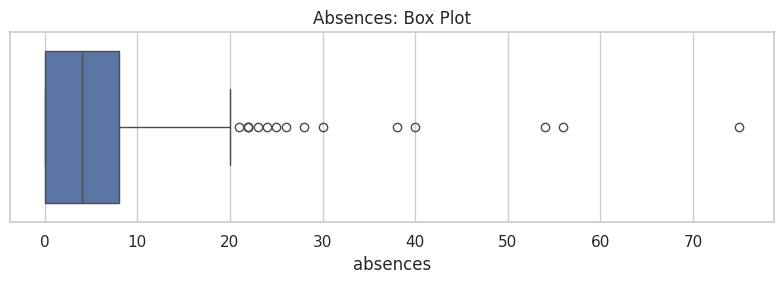

In [29]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["absences"])
plt.title("Absences: Box Plot")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "absences_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.5 Correlation Heatmap

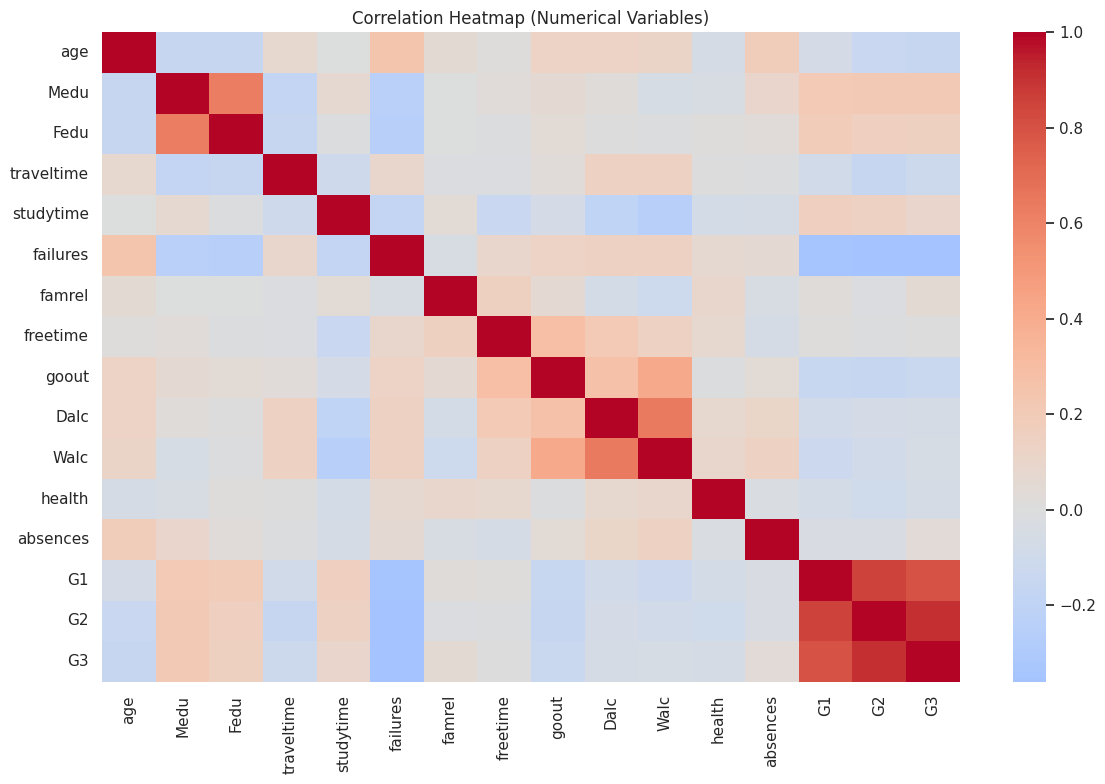

In [30]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numerical Variables)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.6 Average Final Grade by Study-Time Category

In [31]:
studytime_average = df.groupby("studytime")["G3"].mean()
studytime_average

,G3
studytime,
1,10.047619
2,10.171717
3,11.400000
4,11.259259


## 5. Data Preprocessing

The target is `G3`. The columns `G1` and `G2` are kept as input features because earlier-period grades are assumed to be available when predicting the final grade. We split the data before encoding and scaling to avoid using test data to fit preprocessing steps.

In [32]:
# Separate input features (X) and target (y).
X = df.drop(columns=["G3"])
y = df["G3"]

# Split data into 80% training and 20% testing.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train_raw.shape[0])
print("Testing records:", X_test_raw.shape[0])

Training records: 316
Testing records: 79


### 5.1 Convert Categorical Data into Numbers

In [33]:
# One-hot encode categorical columns.
X_train = pd.get_dummies(X_train_raw, drop_first=True)
X_test = pd.get_dummies(X_test_raw, drop_first=True)

# Make sure training and testing data have the same columns.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (316, 41)
Testing feature shape: (79, 41)


### 5.2 Feature Scaling for Linear Regression

StandardScaler is fitted only on the training data. Random Forest will use the encoded but unscaled features.

In [34]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


## 6. Train the Machine Learning Models

We train two models on the same training data. Linear Regression uses scaled features. Random Forest uses the encoded features without scaling.

In [35]:
# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)

# Model 2: Random Forest Regressor
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
random_forest_model.fit(X_train, y_train)
random_forest_predictions = random_forest_model.predict(X_test)

print("Both models have been trained.")

Both models have been trained.


## 7. Evaluate and Compare Models

MAE, MSE, and RMSE measure prediction error (lower is better). R² measures performance relative to a mean-baseline model (higher is generally better).

In [36]:
def calculate_metrics(model_name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted),
    }

comparison = pd.DataFrame([
    calculate_metrics("Linear Regression", y_test, linear_predictions),
    calculate_metrics("Random Forest", y_test, random_forest_predictions),
])

comparison = comparison.sort_values("RMSE").reset_index(drop=True)
comparison

,Model,MAE,MSE,RMSE,R2
0,Random Forest,1.173418,3.867641,1.966632,0.811381
1,Linear Regression,1.646666,5.656643,2.378370,0.724134


In [37]:
# Save the comparison table.
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

print("Model comparison (lower error is better):")
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

Model comparison (lower error is better):
            Model   MAE   MSE  RMSE    R2
    Random Forest 1.173 3.868 1.967 0.811
Linear Regression 1.647 5.657 2.378 0.724


## 8. Visualise Model Comparison

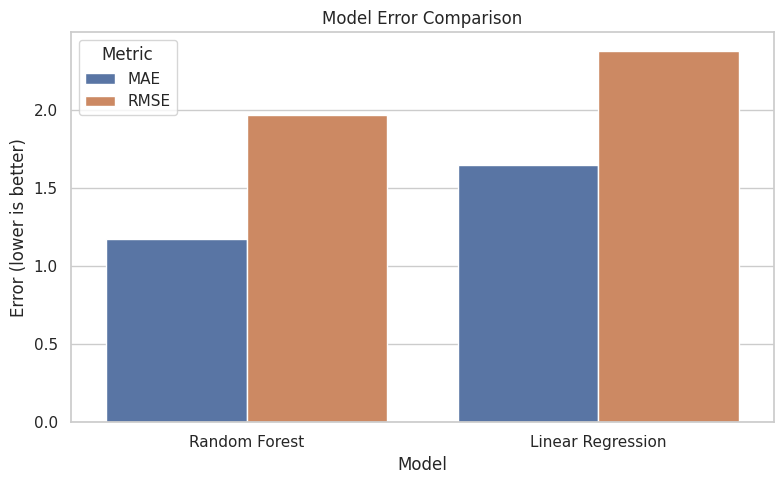

In [38]:
error_data = comparison.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error",
)

plt.figure(figsize=(8, 5))
sns.barplot(data=error_data, x="Model", y="Error", hue="Metric")
plt.title("Model Error Comparison")
plt.ylabel("Error (lower is better)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Actual vs Predicted Grades

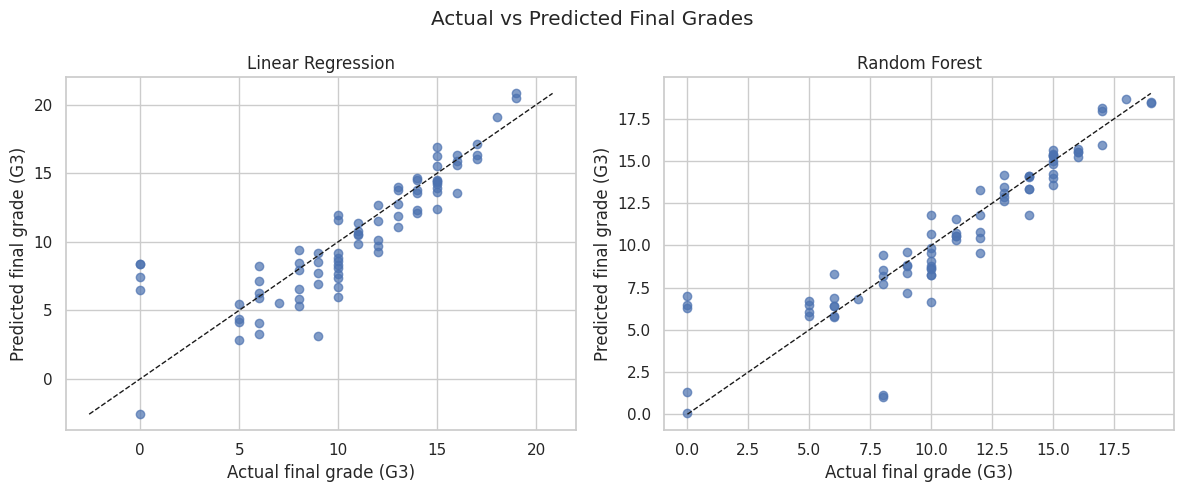

In [39]:
predictions = {
    "Linear Regression": linear_predictions,
    "Random Forest": random_forest_predictions,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, predicted) in zip(axes, predictions.items()):
    ax.scatter(y_test, predicted, alpha=0.7)
    lower = min(float(y_test.min()), float(np.min(predicted)))
    upper = max(float(y_test.max()), float(np.max(predicted)))
    ax.plot([lower, upper], [lower, upper], "k--", linewidth=1)
    ax.set_xlabel("Actual final grade (G3)")
    ax.set_ylabel("Predicted final grade (G3)")
    ax.set_title(model_name)

fig.suptitle("Actual vs Predicted Final Grades")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. View Sample Predictions and Best Test-Set Result

In [40]:
best_model_name = comparison.loc[0, "Model"]
best_predictions = predictions[best_model_name]

sample_results = pd.DataFrame(
    {
        "Actual": y_test.to_numpy(),
        "Predicted": best_predictions,
    },
    index=y_test.index,
)

print("Sample predictions from", best_model_name)
display(sample_results.head(10))
sample_results.to_csv(RESULTS_DIR / "sample_predictions.csv", index_label="Student_Row")

print("Lowest test RMSE in this comparison:", best_model_name)
print("Results saved in:", RESULTS_DIR.resolve())

Sample predictions from Random Forest


,Actual,Predicted
78,10,8.240
371,12,11.770
248,5,6.725
55,10,9.560
390,9,8.820
223,13,12.850
42,18,18.685
234,6,6.855
316,0,7.005
116,14,13.345


Lowest test RMSE in this comparison: Random Forest
Results saved in: /content/results


## 11. Conclusion and Limitations

- This project demonstrates data inspection, EDA, preprocessing, model training, and evaluation.
- Linear Regression provides a simple baseline. Random Forest provides a second model for comparison.
- Use the metric table above to decide which model performed better on this particular test split; do not assume one model is always best.
- The dataset contains 395 Mathematics student records, so results may not generalise to other schools or student groups.
- `G1` and `G2` are included as inputs. This means the prediction is made with earlier-period grades available. A prediction task without earlier grades would need a separate experiment.
- The box plot is used to inspect possible outliers; high-absence records are not automatically removed.
- These predictions are for academic learning and should not be used alone for high-stakes decisions about students.

**Dataset source:** [UCI Machine Learning Repository — Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)  
**Dataset citation:** Cortez, P. (2008). *Student Performance* [Dataset]. https://doi.org/10.24432/C5TG7T.